# ACC_Modeling: Physics-Informed Sparse Identification of Vehicle Dynamics
**Stage 2 Milestone — Whole-Vehicle Planar Force & Friction-Ellipse Formulation ($[a_y, a_x, v, \eta_P] \to \dot{r}$)**

This notebook demonstrates the modular `ACC_Modeling` (`src`) pipeline evaluated on **200 Hz ACC MoTeC telemetry** at **Circuit de Barcelona-Catalunya** for two controlled Audi R8 chassis:
- **High-Downforce Prototype**: Audi R8 LMS GT3 Evo II (`configs/cars/audi_r8_gt3_evo2/vehicle.yaml`)
- **Mechanical-Grip Baseline**: Audi R8 LMS GT4 (`configs/cars/audi_r8_gt4/vehicle.yaml`)

### Pipeline Overview
1. **Data Curation**: Unit-aware SI conversion, continuous session trimming (`SPEED >= 100 km/h` for practice; `first_beacon` for race), Savitzky-Golay (`window=21, poly=3`) smoothing & analytical differentiation ($\dot{r}, \dot{a}_y$), and tire-pressure grip factor $\eta_P(t)$.
2. **Planar Force Identification (`PlanarForceLibrary`)**: PySINDy `STLSQ` regression on the 8-term physics-informed yaw-acceleration library.
3. **Statistical Stress-Testing & Physical Corner Mapping**: Residual Gaussianity & Type-I Omission Sweep, Moving-Block Bootstrap (95% CI & $p$-values), and Race $>5\sigma_0$ outlier georeferencing.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from src.cli import run_pipeline
print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/ACC_Modeling


## 1. Audi R8 LMS GT3 Evo II — Practice Identification & Race Stress-Test

In [2]:
gt3_report = run_pipeline("configs/experiments/stage2_planar_force/barcelona__audi_r8_gt3_evo2__r8_A.yaml")
print("Identified ODE:", gt3_report["equation"])
print(f"Clean Practice: R^2 = {gt3_report['clean_metrics']['r2']:.4f}, RMSE = {gt3_report['clean_metrics']['rmse']:.4f} rad/s^2")
print(f"Race Stress-Test: R^2 = {gt3_report['race_metrics']['r2']:.4f}, Within ±3σ = {gt3_report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: stage2_barcelona_gt3_r8_A (Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=16.510s, 218865 -> 215563 rows)


INFO: Identified ODE: dr/dt = +0.80212 * r -0.37523 * a_y +0.32178 * a_y_dot -4.71760 * a_y_dot/v -0.01675 * a_y-v*r -0.00897 * a_y*|a_x| +0.00624 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.64429 * r*|r|


INFO: Clean Practice R^2=0.1901 | RMSE=1.0252 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Trimmed at first_beacon t=85.184s (148594 -> 131557 rows)


INFO: Race Stress-Test R^2=0.1866 | Within ±3σ=98.50% | >5σ=425


INFO: Artifacts saved to outputs/stage2_barcelona_gt3_r8_A


Identified ODE: dr/dt = +0.80212 * r -0.37523 * a_y +0.32178 * a_y_dot -4.71760 * a_y_dot/v -0.01675 * a_y-v*r -0.00897 * a_y*|a_x| +0.00624 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.64429 * r*|r|
Clean Practice: R^2 = 0.1901, RMSE = 1.0252 rad/s^2
Race Stress-Test: R^2 = 0.1866, Within ±3σ = 98.50%


In [3]:
display(Markdown("### GT3 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(gt3_report["bootstrap"]["terms"]))

display(Markdown("### GT3 Type-I Error (Omission) Sweep — Clean Practice"))
display(pd.DataFrame(gt3_report["clean_metrics"]["diagnostics"]["omission_sweep"]))

display(Markdown("### GT3 Race >5σ Anomaly Corner Mapping"))
display(pd.Series(gt3_report["race_metrics"]["corner_anomalies"], name="Anomaly Frames").to_frame())

### GT3 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,r,0.802120,0.811258,0.324463,0.209311,1.499881,2.472145,1.376293e-02
1,a_y,-0.375232,-0.372826,0.077748,-0.527084,-0.233936,-4.826227,1.852283e-06
2,a_y_dot,0.321785,0.320303,0.033950,0.259889,0.390303,9.478285,1.043272e-19
3,a_y_dot/v,-4.717597,-4.639031,1.053621,-6.751587,-2.644659,-4.477506,9.367822e-06
4,a_y-v*r,-0.016746,-0.016329,0.006881,-0.029397,-0.002018,-2.433815,1.529052e-02
5,a_y*|a_x|,-0.008974,-0.009719,0.021392,-0.050320,0.030086,-0.419494,6.750358e-01
6,a_y*(a_x^2+a_y^2)/eta_P^2,0.006244,0.006268,0.008559,-0.009625,0.022986,0.729464,4.660602e-01
7,r*|r|,-0.644287,-0.655583,0.308708,-1.305786,-0.040779,-2.087042,3.739118e-02


### GT3 Type-I Error (Omission) Sweep — Clean Practice

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,68400.405006,44440,31.731051,20.615783
1,2.0,9808.173386,11350,4.550026,5.265282
2,2.5,2677.148173,6479,1.241933,3.005618
3,3.0,581.976139,3930,0.269980,1.823133
4,3.5,100.292444,2421,0.046526,1.123106
5,4.0,13.654296,1543,0.006334,0.715800
6,5.0,0.123583,691,0.000057,0.320556


### GT3 Race >5σ Anomaly Corner Mapping

,Anomaly Frames
T9 Campsa,148
T11-T14 Sector 3,118
T4 Repsol,60
T7-T8 Chicane,43
T10 La Caixa,29
T5 Seat,21
T3 Renault,6


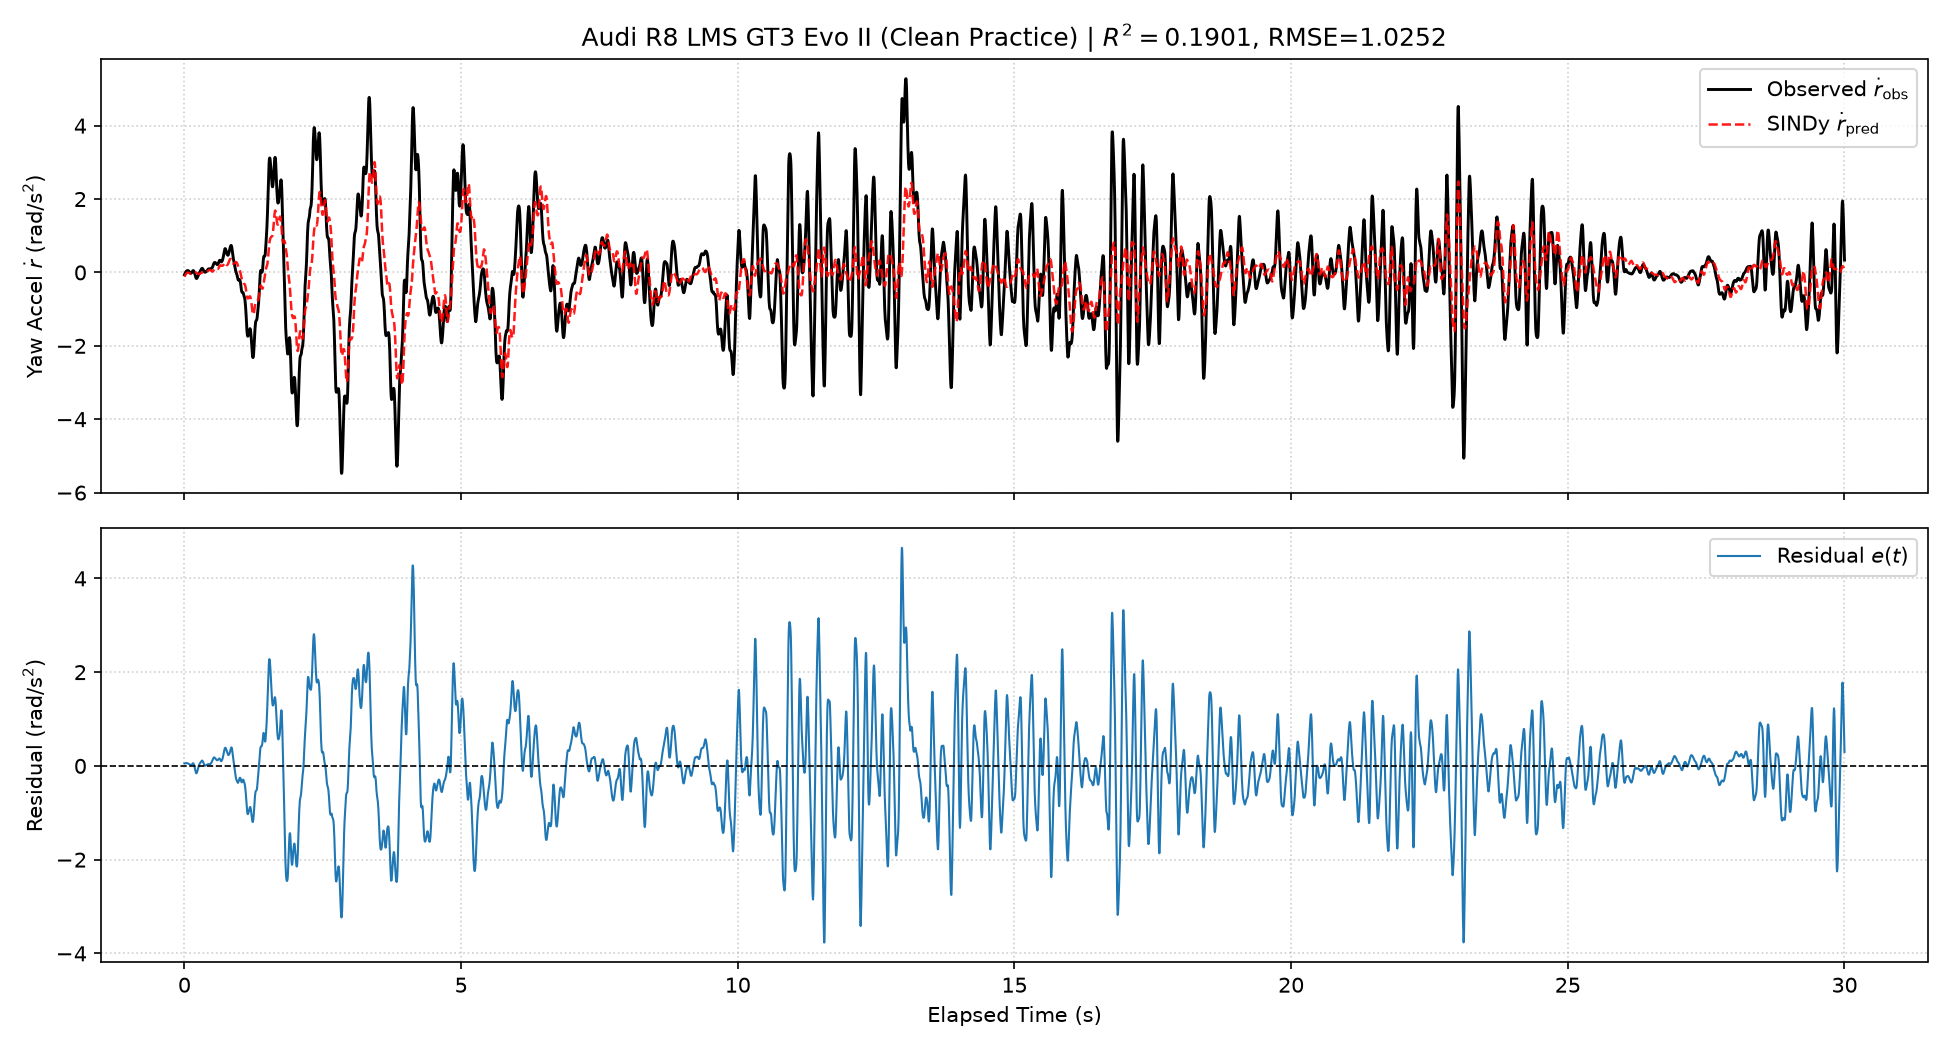

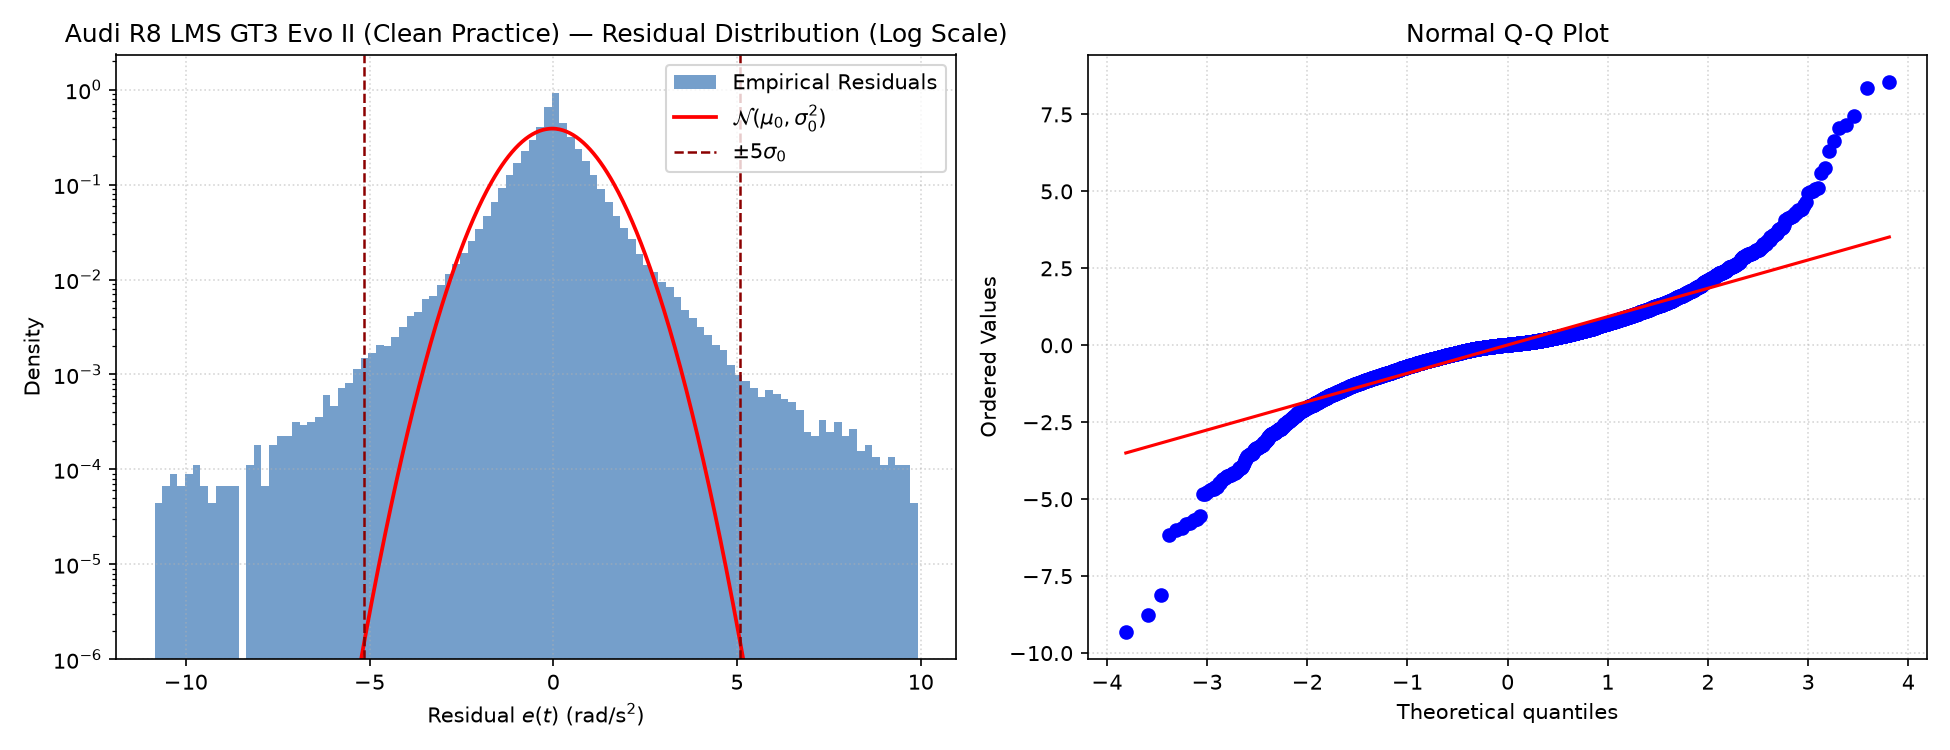

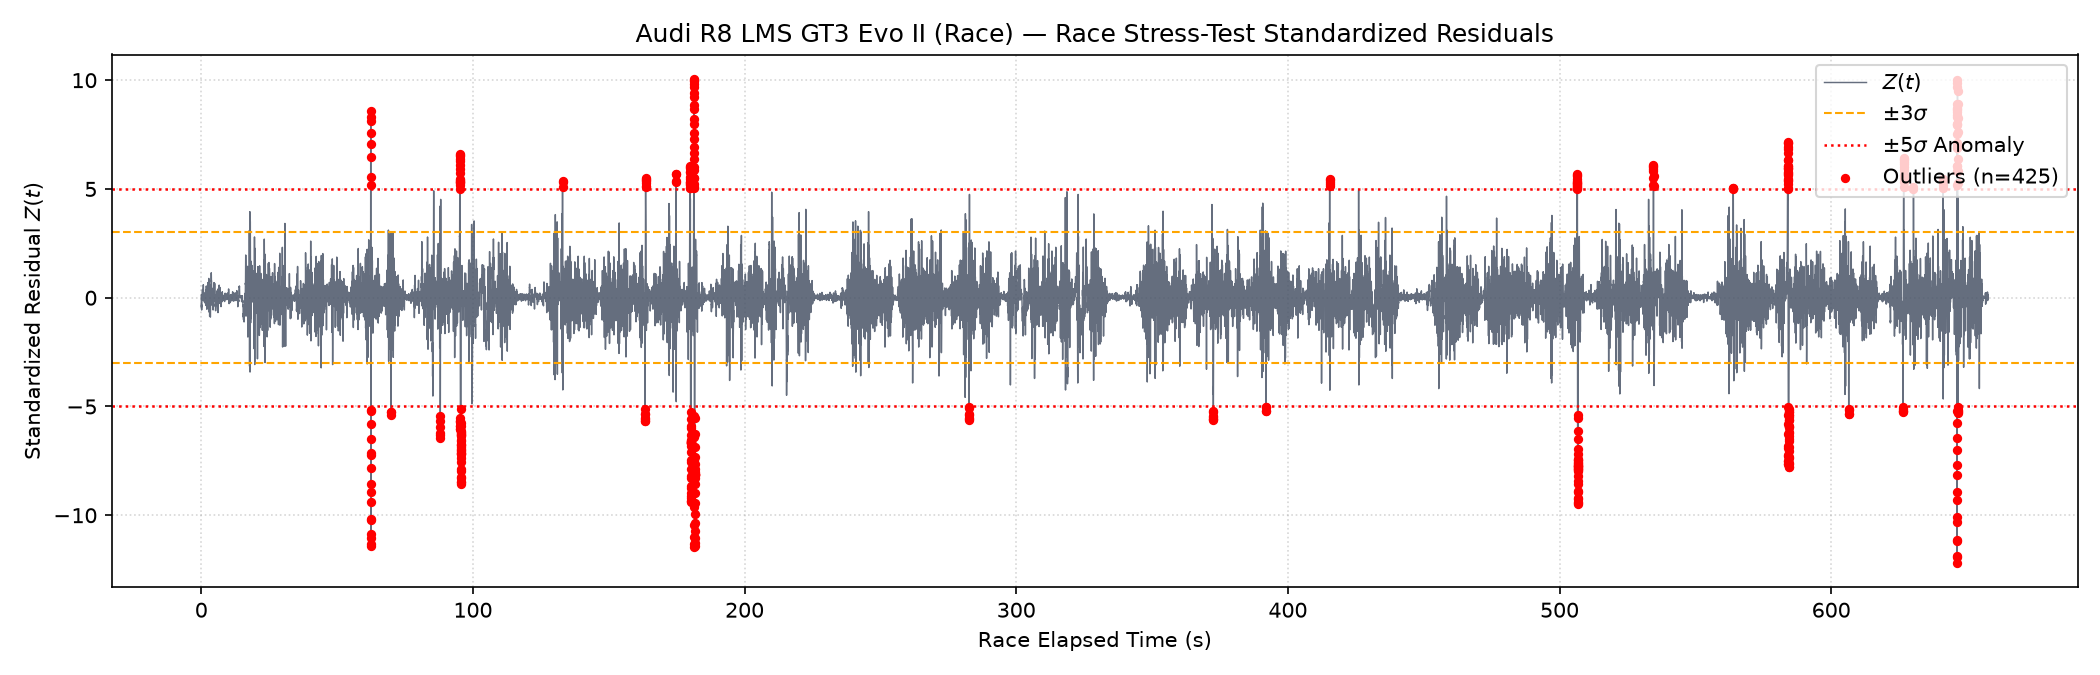

In [4]:
gt3_out = Path("outputs/stage2_barcelona_gt3_r8_A")
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png", "race_anomaly_trace.png"]:
    display(Image(filename=str(gt3_out / img_name)))

## 2. Audi R8 LMS GT4 — Mechanical-Grip Baseline

In [5]:
gt4_report = run_pipeline("configs/experiments/stage2_planar_force/barcelona__audi_r8_gt4__a1.yaml")
print("Identified ODE:", gt4_report["equation"])
print(f"Clean Practice: R^2 = {gt4_report['clean_metrics']['r2']:.4f}, RMSE = {gt4_report['clean_metrics']['rmse']:.4f} rad/s^2")
print(f"Race Stress-Test: R^2 = {gt4_report['race_metrics']['r2']:.4f}, Within ±3σ = {gt4_report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: stage2_barcelona_gt4_a1 (Audi R8 LMS GT4 @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=25.525s, 256828 -> 251723 rows)


INFO: Identified ODE: dr/dt = +0.88322 * r -0.23335 * a_y +0.37507 * a_y_dot -4.45801 * a_y_dot/v -0.00016 * a_y-v*r -0.00953 * a_y*|a_x| -0.00000 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.67212 * r*|r|


INFO: Clean Practice R^2=0.2849 | RMSE=0.7212 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Trimmed at first_beacon t=65.664s (155093 -> 141960 rows)


INFO: Race Stress-Test R^2=0.2472 | Within ±3σ=98.00% | >5σ=685


INFO: Artifacts saved to outputs/stage2_barcelona_gt4_a1


Identified ODE: dr/dt = +0.88322 * r -0.23335 * a_y +0.37507 * a_y_dot -4.45801 * a_y_dot/v -0.00016 * a_y-v*r -0.00953 * a_y*|a_x| -0.00000 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.67212 * r*|r|
Clean Practice: R^2 = 0.2849, RMSE = 0.7212 rad/s^2
Race Stress-Test: R^2 = 0.2472, Within ±3σ = 98.00%


In [6]:
display(Markdown("### GT4 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(gt4_report["bootstrap"]["terms"]))

display(Markdown("### GT4 Type-I Error (Omission) Sweep — Clean Practice"))
display(pd.DataFrame(gt4_report["clean_metrics"]["diagnostics"]["omission_sweep"]))

display(Markdown("### GT4 Race >5σ Anomaly Corner Mapping"))
display(pd.Series(gt4_report["race_metrics"]["corner_anomalies"], name="Anomaly Frames").to_frame())

### GT4 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,r,8.832198e-01,9.003928e-01,3.921989e-01,2.014722e-01,1.751279e+00,2.251969,2.475822e-02
1,a_y,-2.333513e-01,-2.379350e-01,7.570258e-02,-3.946922e-01,-9.472571e-02,-3.082474,2.166417e-03
2,a_y_dot,3.750692e-01,3.677898e-01,3.087572e-02,3.038892e-01,4.185420e-01,12.147708,6.289846e-30
3,a_y_dot/v,-4.458009e+00,-4.241569e+00,8.561163e-01,-5.557565e+00,-2.262625e+00,-5.207246,2.807179e-07
4,a_y-v*r,-1.559020e-04,-4.168734e-04,7.056751e-03,-1.369615e-02,1.323783e-02,-0.022093,9.823829e-01
5,a_y*|a_x|,-9.531803e-03,-9.652914e-03,2.978878e-02,-6.470388e-02,4.558691e-02,-0.319980,7.491177e-01
6,a_y*(a_x^2+a_y^2)/eta_P^2,-1.083474e-07,-1.272095e-07,1.231722e-07,-4.250613e-07,7.914440e-09,-0.879641,3.794771e-01
7,r*|r|,-6.721218e-01,-6.919680e-01,3.572767e-01,-1.498413e+00,-8.467536e-02,-1.881236,6.052179e-02


### GT4 Type-I Error (Omission) Sweep — Clean Practice

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,79874.352971,52736,31.731051,20.950013
1,2.0,11453.462929,12825,4.550026,5.094886
2,2.5,3126.231170,6556,1.241933,2.604450
3,3.0,679.600764,3721,0.269980,1.478212
4,3.5,117.116179,2254,0.046526,0.895429
5,4.0,15.944760,1526,0.006334,0.606222
6,5.0,0.144314,811,0.000057,0.322180


### GT4 Race >5σ Anomaly Corner Mapping

,Anomaly Frames
T11-T14 Sector 3,330
T3 Renault,126
T10 La Caixa,102
T7-T8 Chicane,71
T5 Seat,51
T1-T2 Elf,5


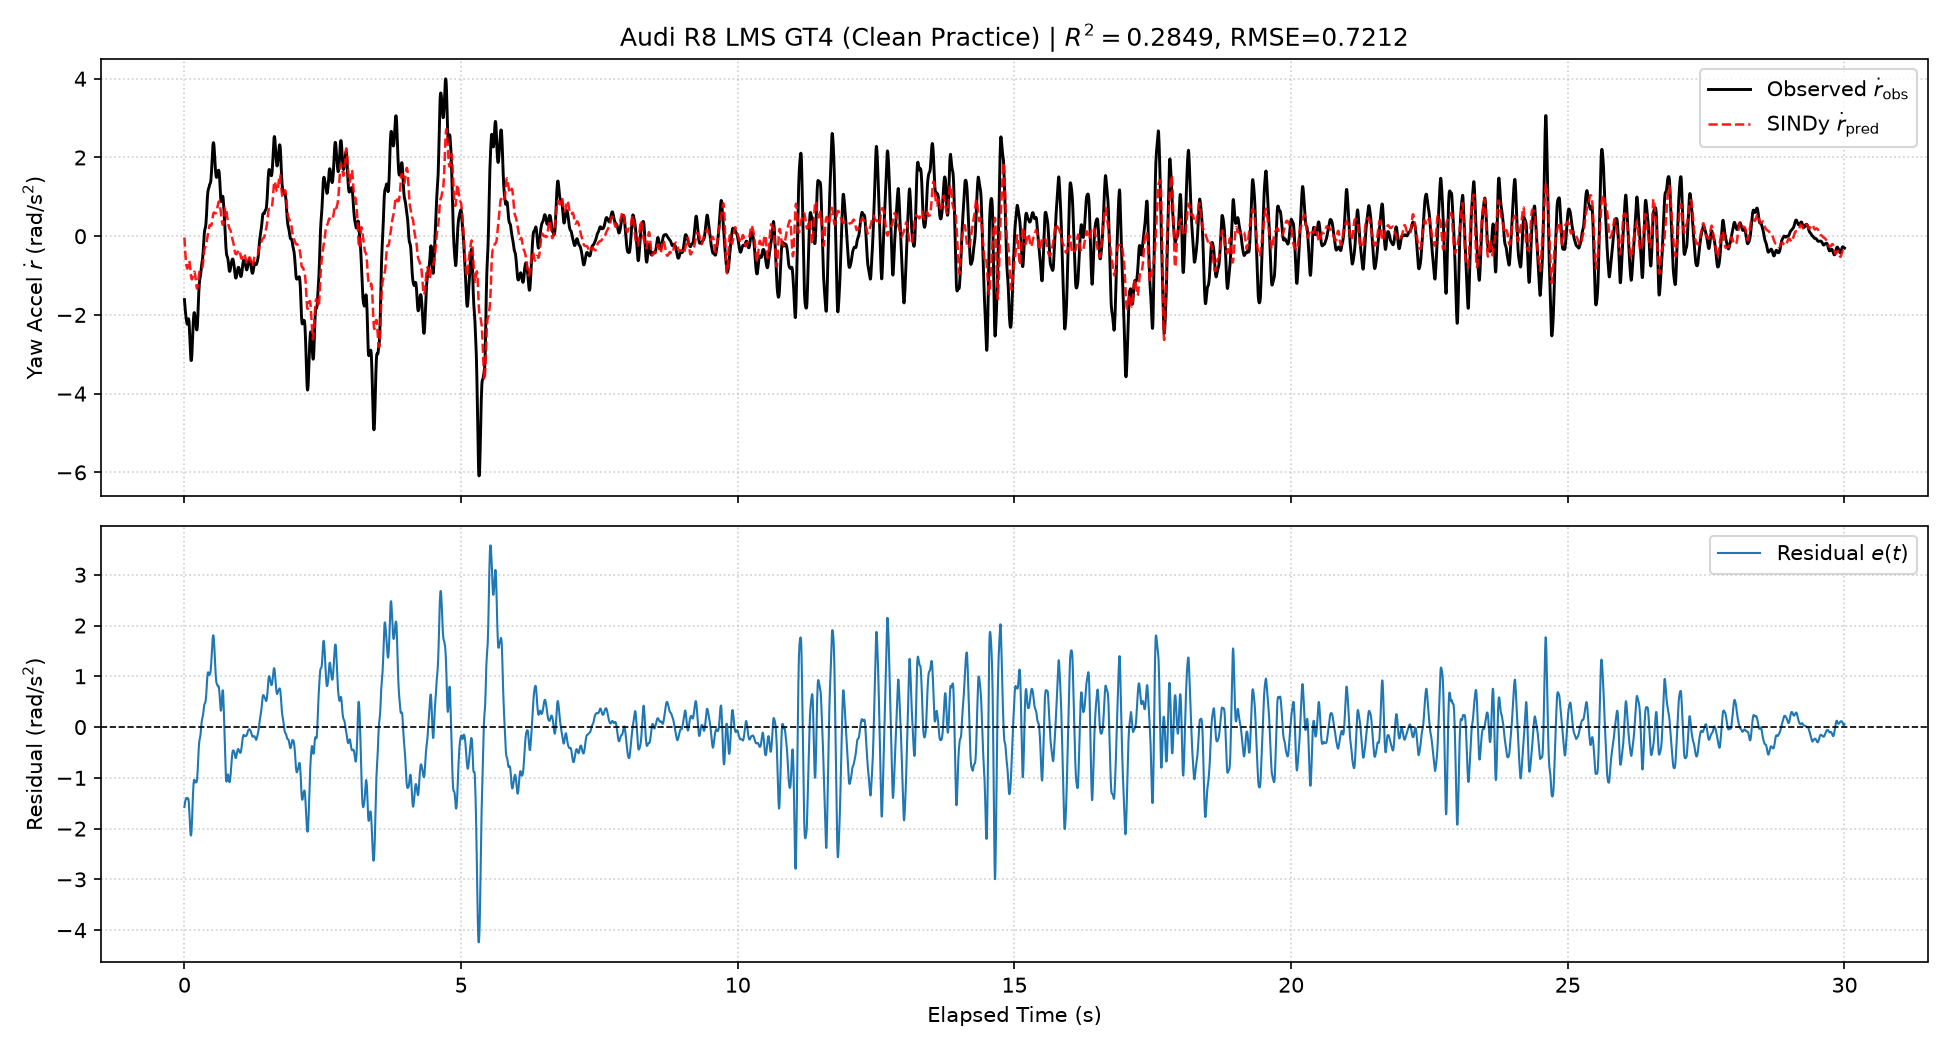

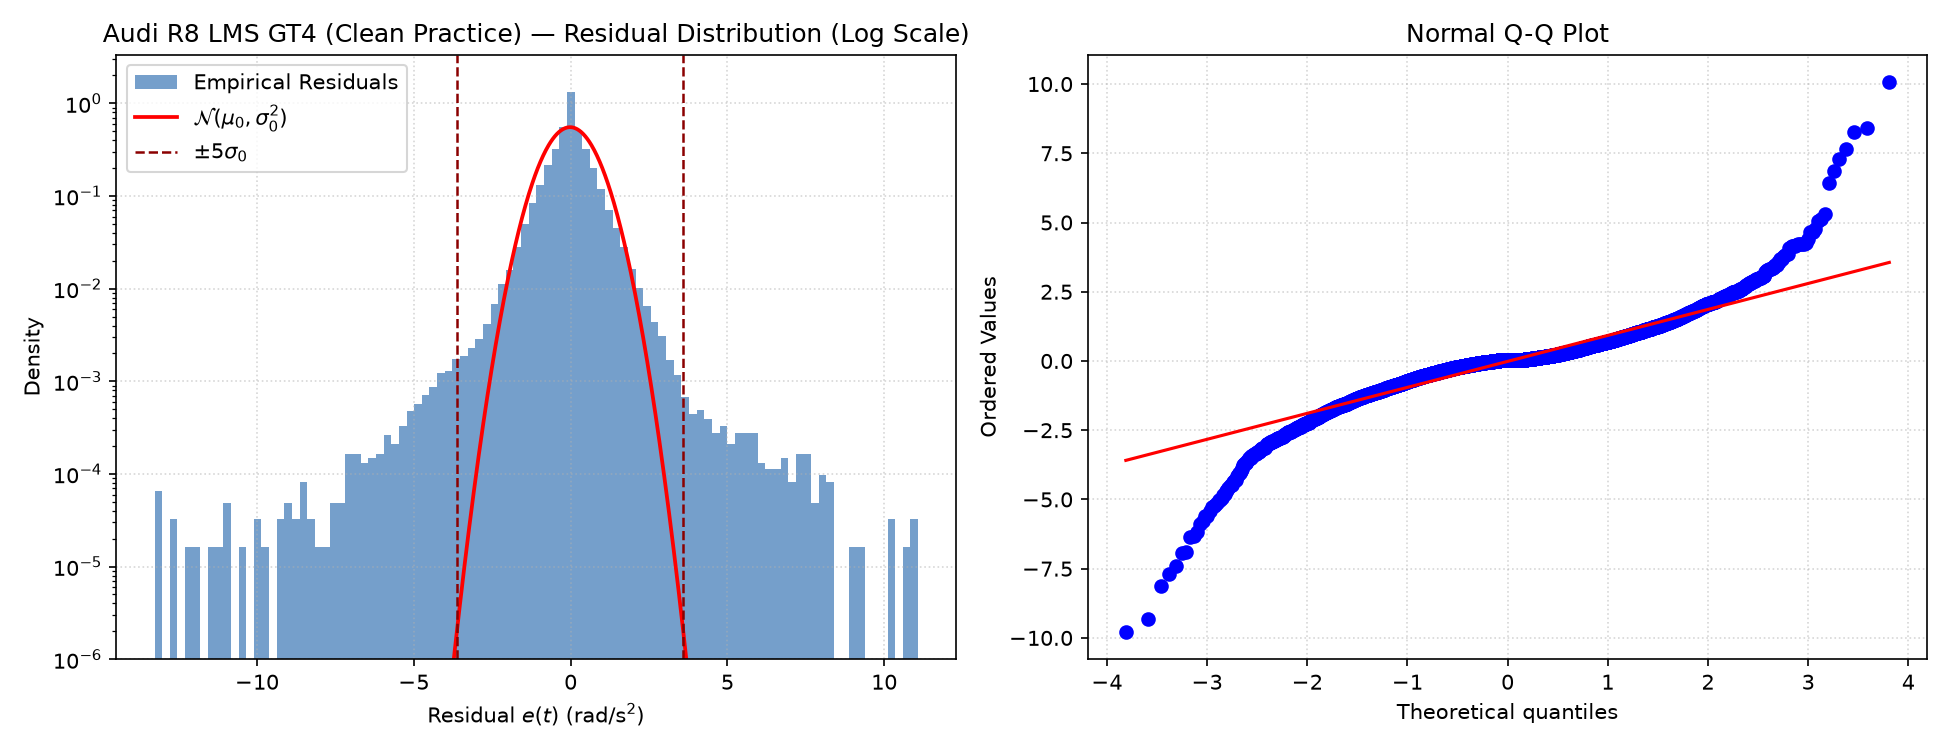

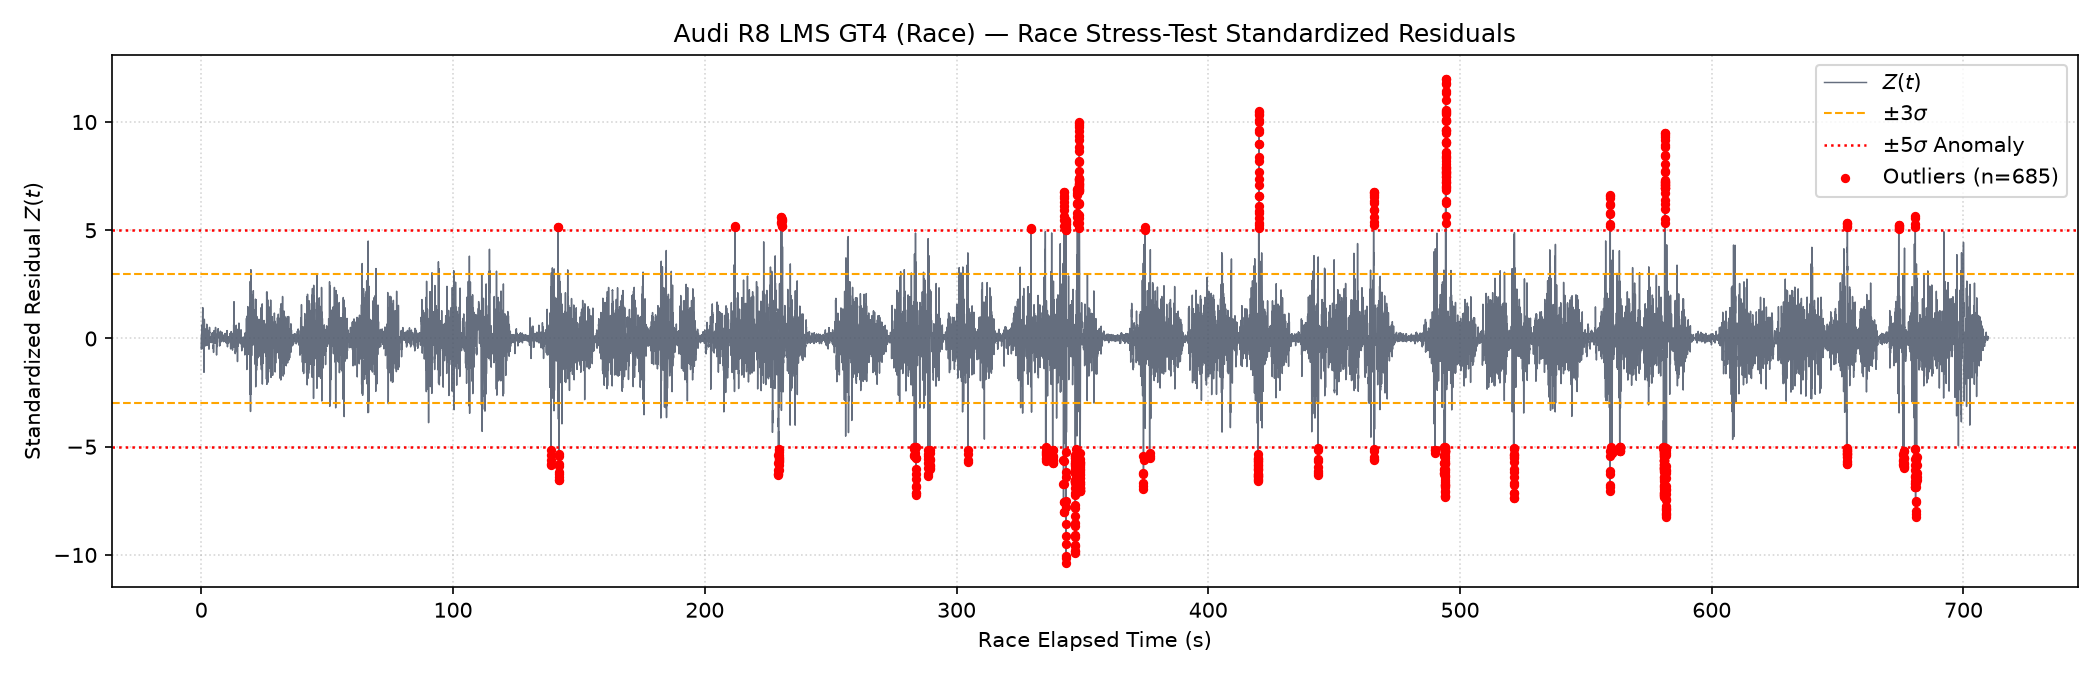

In [7]:
gt4_out = Path("outputs/stage2_barcelona_gt4_a1")
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png", "race_anomaly_trace.png"]:
    display(Image(filename=str(gt4_out / img_name)))